# Workshop 3 - Data-quality findings in the Silver layer (Team 2, Flood Monitoring and Risk, Texas)

This notebook reviews the Bronze JSON files and the Silver Parquet files with **Pandas** and documents the
data-quality findings that justify (a) the Workshop 3 pipeline improvements and (b) the governance KPIs of the
Gold layer: descriptive statistics, null rates, outliers and text lengths, plus a before/after comparison of
the text preprocessing.

Findings are numbered **W3-1 ... W3-10** as in the Workshop 3 report. Figures are saved to `notebooks/figures/`.

In [1]:
import json, re, collections
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
BRONZE, SILVER = ROOT / "datalake_bronze", ROOT / "datalake_silver"
FIG = ROOT / "notebooks" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 9})
TOPICS = ["nws_observations", "nws_alerts", "daily_precipitation", "flood_events"]
silver = {t: pd.concat([pd.read_parquet(f) for f in sorted(SILVER.glob(f"{t}_*.parquet"))], ignore_index=True)
          for t in TOPICS}
bronze_files = sorted(BRONZE.glob("texas_flood_sources_*.json"))
inv = pd.DataFrame([{"topic": t, "silver_files": len(list(SILVER.glob(f"{t}_*.parquet"))), "rows": len(df),
                     "columns": df.shape[1]} for t, df in silver.items()])
print(len(bronze_files), "Bronze files"); inv

9 Bronze files


,topic,silver_files,rows,columns
0,nws_observations,6,372,30
1,nws_alerts,2,61,37
2,daily_precipitation,2,30786,20
3,flood_events,1,8000,40


## 1. Descriptive statistics of the numeric fields

In [2]:
num_cols = {"nws_observations": ["precip_1h_mm", "temperature_c", "relative_humidity_pct"],
            "daily_precipitation": ["prcp_mm"],
            "flood_events": ["damage_property_usd", "duration_hours", "narrative_word_count",
                             "deaths_direct", "injuries_direct"],
            "nws_alerts": ["description_word_count"]}
stats = pd.concat({t: silver[t][c].describe(percentiles=[.25, .5, .75, .95, .99]).T for t, c in num_cols.items()})
stats.round(2)

count        mean           std    min    25%    50%     75%       95%         99%           max
nws_observations    precip_1h_mm               55.0        0.00  0.000000e+00   0.00   0.00    0.0    0.00       0.0        0.00  0.000000e+00
                    temperature_c             372.0       12.39  4.300000e+00   4.00   8.00   13.0   16.02      19.0       19.12  2.000000e+01
                    relative_humidity_pct     372.0       65.98  1.945000e+01  30.83  48.03   70.5   81.49      93.4      100.00  1.000000e+02
daily_precipitation prcp_mm                 30786.0        2.50  1.028000e+01   0.00   0.00    0.0    0.00      15.5       48.55  4.082000e+02
flood_events        damage_property_usd      7937.0  6172936.22  2.041680e+08   0.00   0.00    0.0    0.00  100000.0  6628000.00  1.000000e+10
                    duration_hours           8000.0        6.53  3.122000e+01   0.00   1.00    2.0    3.50      14.0      112.33  7.199800e+02
                    narrative_word_count     8000.0       31.23  3.840000e+01   3.00  14.00   21.0   32.00      92.0      192.02  7.770000e+02
                    deaths_direct            8000.0        0.05  1.000000e+00   0.00   0.00    0.0    0.00       0.0        1.00  6.100000e+01
                    injuries_direct          8000.0        0.00  9.000000e-02   0.00   0.00    0.0    0.00       0.0        0.00  4.000000e+00
nws_alerts          description_word_count     61.0      109.66  6.019000e+01  12.00  61.00  132.0  154.00     182.0      217.20  2.520000e+02

## 2. Null rates per field (all topics)

,topic,field,null_pct
7,nws_observations,precip_3h_mm,100.00
8,nws_observations,precip_6h_mm,100.00
6,nws_observations,precip_1h_mm,85.22
23,nws_observations,severity_level,85.22
76,daily_precipitation,prcp_zscore,77.70
118,flood_events,impact_terms,58.74
48,nws_alerts,reference_ids,44.26
59,nws_alerts,impact_terms,37.70
102,flood_events,damage_property_usd,0.79
103,flood_events,damage_crops_usd,0.54


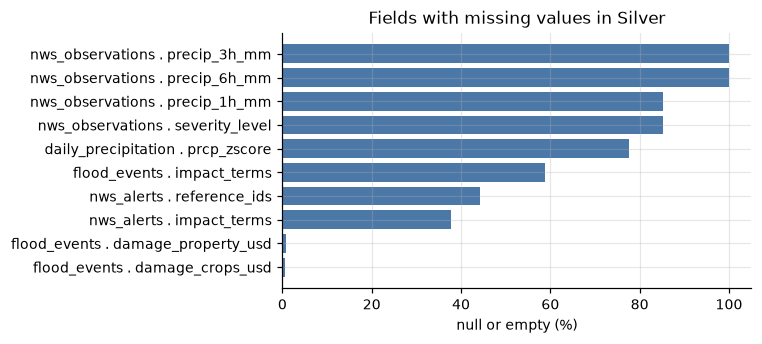

In [3]:
def null_rate(df):
    out = {}
    for c in df.columns:
        s = df[c]
        if s.map(lambda v: isinstance(v, (list, np.ndarray))).any():
            out[c] = s.map(lambda v: v is None or len(v) == 0).mean() * 100
        else:
            out[c] = s.isna().mean() * 100
    return pd.Series(out)
nulls = pd.concat({t: null_rate(df) for t, df in silver.items()}).rename("null_pct").reset_index()
nulls.columns = ["topic", "field", "null_pct"]
nz = nulls[nulls.null_pct > 0].sort_values("null_pct", ascending=False)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(nz.topic + " . " + nz.field, nz.null_pct, color="#4C78A8")
ax.invert_yaxis(); ax.set_xlabel("null or empty (%)"); ax.set_title("Fields with missing values in Silver")
fig.tight_layout(); fig.savefig(FIG / "w3_null_rates.png"); nz.round(2)

**W3-1. Hourly rainfall of the NWS observations.** In Workshop 2 the Silver rainfall was 100 % null.
The raw JSON shows two different situations: 5-minute reports do not contain the `precipitationLastHour` key at all,
and hourly METAR reports contain it with `value = null` when it did not rain. The METAR text (`rawMessage`) of an
automated station (`AO2`) only carries a `Pxxxx` group when rain fell, so an hourly report without it means 0 mm.

In [4]:
obs_props = [f["properties"] for b in bronze_files for v in (json.loads(b.read_text())["nws_observations"] or {}).values()
             for f in v]
raw_obs = pd.DataFrame({"has_key": ["precipitationLastHour" in p for p in obs_props],
                        "is_metar": [bool(p.get("rawMessage")) for p in obs_props],
                        "api_value": [(p.get("precipitationLastHour") or {}).get("value") for p in obs_props],
                        "maintenance": [str(p.get("rawMessage") or "").rstrip().endswith("$") for p in obs_props]})
print(pd.crosstab(raw_obs.is_metar, raw_obs.has_key, margins=True))
print("METAR reports with a numeric API value:", raw_obs.api_value.notna().sum())
o = silver["nws_observations"]
print(o.groupby("is_metar").precip_1h_mm.apply(lambda s: s.isna().mean() * 100).rename("null % after v0.3"))
o.precip_source.value_counts()

has_key   False  True  All
is_metar                  
False       565     0  565
True          0    90   90
All         565    90  655
METAR reports with a numeric API value: 0
is_metar
False    100.0
True       0.0
Name: null % after v0.3, dtype: float64


precip_source
missing             317
metar_no_p_group     55
Name: count, dtype: int64

**W3-2. Sensor maintenance flag.** METAR reports that end with `$` come from a station that needs maintenance.

In [5]:
o.groupby("station_id").maintenance_flag.mean().mul(100).round(1).rename("% reports with $")

station_id
KAUS     8.1
KCRP     6.0
KDFW     0.0
KIAH     0.0
KSAT    12.9
Name: % reports with $, dtype: float64

## 3. Outliers
**GHCN-Daily rainfall** is zero-inflated (most days are dry), so outliers are measured on wet days only; the
Z-score uses log(1 + PRCP). **Storm Events** damage is spread over 7 orders of magnitude (log10) and some events
last for weeks (**W3-6**: event duration).

damage outliers: 74 | duration outliers: 165 | longest event (h): 719.98


,days,dry_pct,trace_pct,wet_p99,max_mm,iqr_flags,z_flags
station_id,,,,,,,
KAUS,6158,78.78,13.95,88.47,317.2,57,2
KCRP,6158,78.78,14.92,81.90,181.9,64,1
KDFW,6156,78.78,9.84,83.68,148.6,34,0
KIAH,6157,72.96,12.90,95.61,408.2,46,2
KSAT,6157,79.23,15.49,76.92,250.7,69,1


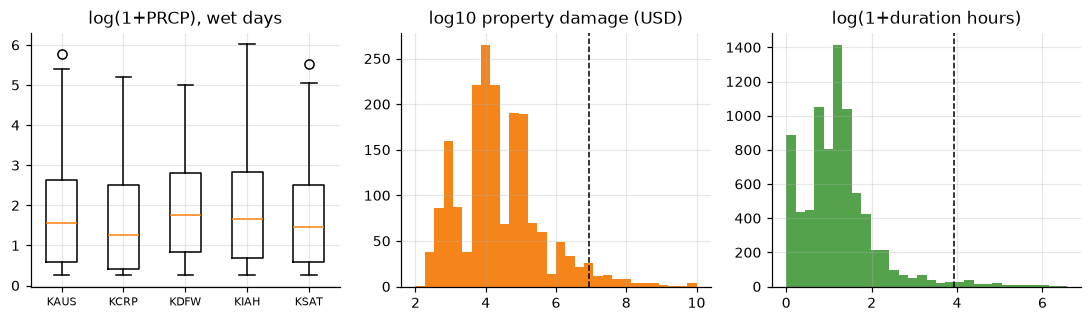

In [6]:
g = silver["daily_precipitation"]
summary = g.groupby("station_id").agg(days=("prcp_mm", "size"), dry_pct=("prcp_mm", lambda s: (s == 0).mean() * 100),
                                      trace_pct=("is_trace", lambda s: s.mean() * 100),
                                      wet_p99=("prcp_mm", lambda s: s[s > 0].quantile(.99)),
                                      max_mm=("prcp_mm", "max"), iqr_flags=("is_outlier_iqr", "sum"),
                                      z_flags=("is_outlier_z", "sum"))
fe = silver["flood_events"]
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
wet = g[g.prcp_mm > 0]
axes[0].boxplot([np.log1p(wet[wet.station_id == s].prcp_mm) for s in summary.index])
axes[0].set_xticks(range(1, len(summary) + 1)); axes[0].set_xticklabels(summary.index)
axes[0].set_title("log(1+PRCP), wet days"); axes[0].tick_params(axis="x", labelsize=7)
d = np.log10(fe.damage_property_usd[fe.damage_property_usd > 0])
axes[1].hist(d, bins=30, color="#F58518"); axes[1].set_title("log10 property damage (USD)")
axes[1].axvline(d.quantile(.75) + 1.5 * (d.quantile(.75) - d.quantile(.25)), color="k", ls="--", lw=1)
h = np.log1p(fe.duration_hours.dropna())
axes[2].hist(h, bins=30, color="#54A24B"); axes[2].set_title("log(1+duration hours)")
axes[2].axvline(h.quantile(.75) + 3 * (h.quantile(.75) - h.quantile(.25)), color="k", ls="--", lw=1)
fig.tight_layout(); fig.savefig(FIG / "w3_outliers.png")
print("damage outliers:", int(fe.is_outlier_damage.sum()), "| duration outliers:", int(fe.is_outlier_duration.sum()),
      "| longest event (h):", fe.duration_hours.max())
summary.round(2)

## 4. Text: encoding, repetition and length
**W3-3 encoding.** Some NOAA narratives contain the Unicode replacement character U+FFFD where a dash, apostrophe
or accented letter was lost. **W3-5 repetition.** The episode narrative is copied into every event of the episode,
so concatenating it to the event narrative (Workshop 2) counted the same words many times.

In [7]:
storm_raw = pd.DataFrame(json.loads(bronze_files[0].read_text())["storm_events_details"]["records"])
ev, ep = storm_raw.EVENT_NARRATIVE.fillna(""), storm_raw.EPISODE_NARRATIVE.fillna("")
bad = (ev + ep).str.contains("\ufffd")
print("records with U+FFFD:", int(bad.sum()), f"({bad.mean() * 100:.2f}%)")
print("examples:", collections.Counter(m for t in (ev + " " + ep)[bad] for m in re.findall(r"\S*\ufffd+\S*", t)).most_common(6))
print("rows whose episode narrative is a copy of another row's:", f"{(1 - ep.nunique() / len(ep)) * 100:.1f}%")
print("events with an empty event narrative:", int((ev.str.strip() == "").sum()))

records with U+FFFD: 125 (1.56%)
examples: [('���training���', 33), ('1���2', 27), ('3���4', 27), ('M��xico', 13), ('��', 13), ('���', 8)]
rows whose episode narrative is a copy of another row's: 75.3%
events with an empty event narrative: 61


,flood_events,nws_alerts
count,8000.0,61.0
mean,31.2,109.7
std,38.4,60.2
min,3.0,12.0
25%,14.0,61.0
50%,21.0,132.0
75%,32.0,154.0
max,777.0,252.0


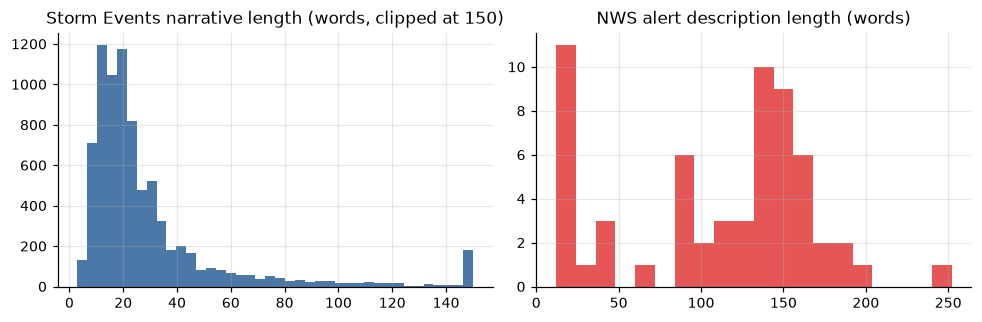

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].hist(fe.narrative_word_count.clip(upper=150), bins=40, color="#4C78A8")
axes[0].set_title("Storm Events narrative length (words, clipped at 150)")
al = silver["nws_alerts"]
axes[1].hist(al.description_word_count, bins=20, color="#E45756"); axes[1].set_title("NWS alert description length (words)")
fig.tight_layout(); fig.savefig(FIG / "w3_text_length.png")
pd.DataFrame({"flood_events": fe.narrative_word_count.describe(), "nws_alerts": al.description_word_count.describe()}).round(1)

**Before / after of the keyword pipeline (W3-4, W3-5).** The Workshop 2 rule (event + episode narrative,
English stop words only, tokens of 2+ letters) is reproduced here on the raw text and compared with the v0.3 tokens.

In [9]:
import sys; sys.path.insert(0, str(ROOT / "src"))
from flood_monitor.text import ENGLISH_STOP_WORDS
def v02_tokens(text):
    t = re.sub(r"[^a-z0-9\s]", " ", text.lower().replace("...", " "))
    return [w for w in t.split() if w not in ENGLISH_STOP_WORDS and len(w) > 1 and not w.isdigit()]
before = collections.Counter(w for t in (ev + " " + ep) for w in set(v02_tokens(t)))
after = collections.Counter(w for toks in fe.narrative_tokens for w in set(toks))
cmp = pd.DataFrame({"v0.2 (W2) term": [w for w, _ in before.most_common(15)],
                    "v0.2 events": [n for _, n in before.most_common(15)],
                    "v0.3 (W3) term": [w for w, _ in after.most_common(15)],
                    "v0.3 events": [n for _, n in after.most_common(15)]})
cmp

,v0.2 (W2) term,v0.2 events,v0.3 (W3) term,v0.3 events
0,flooding,7347,flooding,4350
1,texas,5367,water,3834
2,thunderstorms,5306,road,3794
3,flash,5288,rain,2735
4,heavy,5064,heavy,2715
5,water,4459,flash,2197
6,rain,4454,closed,1767
7,produced,4152,flooded,1701
8,upper,4009,roads,1649
9,county,3806,thunderstorms,1623


## 5. Duplicates and alert redundancy (W3-8)
The manifest of the Silver DAG keeps, per Bronze file and topic, how many rows were offered and how many were
already in Silver. In Workshop 2 every Bronze run downloaded the whole 7-day alert window again.

In [10]:
rows = []
for line in (SILVER / "_manifest.jsonl").read_text().splitlines():
    m = json.loads(line)
    for t, o in m["outputs"].items():
        rows.append({"bronze_file": m["bronze_file"], "topic": t, **{k: o.get(k, 0) for k in
                     ("rows_raw", "filtered_non_flood", "batch_duplicates", "rows_in", "already_in_silver", "rows_written")}})
mf = pd.DataFrame(rows)
dup = mf.groupby("topic")[["rows_in", "batch_duplicates", "already_in_silver", "rows_written"]].sum()
dup["duplicate_pct"] = ((dup.batch_duplicates + dup.already_in_silver) / (dup.rows_in + dup.batch_duplicates) * 100).round(1)
alerts_per_file = mf[mf.topic == "nws_alerts"][["bronze_file", "rows_raw", "rows_written"]]
print(alerts_per_file.to_string(index=False)); dup

                             bronze_file  rows_raw  rows_written
texas_flood_sources_20261116_233000.json       172            60
texas_flood_sources_20261116_234500.json       172             0
texas_flood_sources_20261117_000000.json       172             0
texas_flood_sources_20261117_104500.json        12             1
texas_flood_sources_20261117_110000.json        12             0
texas_flood_sources_20261117_170000.json         1             0
texas_flood_sources_20261117_174500.json         1             0
texas_flood_sources_20261117_180000.json         1             0
texas_flood_sources_20261117_190000.json         3             0


,rows_in,batch_duplicates,already_in_silver,rows_written,duplicate_pct
topic,,,,,
daily_precipitation,31029,0,243,30786,0.8
flood_events,8000,0,0,8000,0.0
nws_alerts,182,0,121,61,66.5
nws_observations,655,0,283,372,43.2


## 6. Summary of findings -> governance KPIs
| # | Field / topic | Issue | Frequency | Handling (Silver v0.3) | Governance KPI |
|---|---|---|---|---|---|
| W3-1 | `precip_1h_mm` (observations) | null in every METAR hour | 100 % of METAR hours in W2 | parse METAR `P` group / AO2 rule | null rate, precip source share |
| W3-2 | `rawMessage` | maintenance `$` | see table | `maintenance_flag` | maintenance flag rate |
| W3-3 | narratives | U+FFFD encoding | 125 records | repair + ASCII folding | encoding repaired rate |
| W3-4 | narrative tokens | generic words dominate keywords | top-15 in W2 | domain stop words, boilerplate | text length, keywords |
| W3-5 | narratives | episode text repeated | 75 % of rows | event narrative only | text length |
| W3-6 | `duration_hours` | events lasting weeks | 165 events | IQR flag (kept) | outlier rate |
| W3-7 | alert description | `* WHAT...` markers | every alert | markers removed | text length |
| W3-8 | alerts | same alerts in every run | 66 % duplicates | incremental window | duplicate rate |
| W3-9 | schema drift | key absent vs null | 85 % of reports | coverage check in Bronze | schema compliance |
| W3-10 | GHCN-Daily | values arrive ~7 days late | 5 stations | 30-day overlap | freshness lag |